# GoSmart DS — Unified Clinical & DICOM `SearchService` Playground

Interactive playground demonstrating the consolidated **`SearchService`** entry point backed by **`ClinicalNLUService`** (`gosmart-clinical-nlu` spaCy model bundle), Neo4j hybrid search (Lucene full-text + HNSW vector search + `[:IS_A]` parent convergence), dynamic schema availability checks, reverse-lookup query rewriting, and Genkit LLM phrase synthesis (`inference-v1` / Ollama `gemma4:e2b`).

**What we demonstrate in this notebook:**
1. **One-Line Service Setup** — initializing `SearchService()` and inspecting active Neo4j vocabularies, NLU model, and `LLM_Config` tags (`embedding-v1`, `inference-v1`)
2. **Free-Text Hybrid Discovery (`NLU` + `gemma4:e2b` Synthesis)** — discovering both clinical terminologies and DICOM attributes from natural language, comparing LLM expansion on vs. off
3. **Deterministic Code Extraction, Reverse-Lookup Rewriting & Score Tiers** — single- and multi-code queries (`LOINC`, `ICD-10`, `SNOMED`, `DICOM` tags/UIDs) returning Tier 1 exact hits (`score = 1.0`) above discounted Tier 2 (`rewritten_query`, `<= 0.85`) and Tier 3 (`synthesized_phrases`, `<= 0.78`) discovery results, with a score-tier visualization
4. **Dynamic Schema Alerts & Unknown Code Guardrails** — warning on unloaded vocabularies (e.g., `RxNorm`) and stripping unknown codes (e.g., `LOINC 999999-9`) to prevent LLM hallucination
5. **Ontology & Relationship Intents** — natural-language related lookup, cross-terminology crosswalk, subtype ValueSet expansion, `$subsumes`, and direct `lookup_code` / `lookup_dicom` calls
6. **Wire Formats (`FULL`, `COMPACT` for MCP, `FHIR` for REST) & Latency Benchmark Chart** — comparing payloads and visualising latency + entity mix across scenarios
7. **Interactive Ad-Hoc Playground Helper** — `await play("your query here")` for quick experimentation

## 1. Initialize `SearchService` & Inspect Active Pipeline Configuration

With the consolidated API, creating `SearchService()` wires up:
- **Neo4j** connection from `.env`
- **`ClinicalNLUService`** backed by the trained `gosmart-clinical-nlu` bundle (`nlu_models/intent_models.zip`)
- **`EmbeddingService`** (`embedding-v1`) for DICOM HNSW vector search & on-the-fly clinical reranking
- **Genkit LLM synthesis** (`inference-v1`, defaulting to Ollama `gemma4:e2b`) for alternate clinical/DICOM phrase generation

Let's initialize the service, verify connectivity, inspect the active schemas loaded in Neo4j, and define reusable display helpers.

In [20]:
import logging
from typing import Any, Optional

import matplotlib.pyplot as plt
import pandas as pd

from gosmart_dictionary_service.core.config import get_settings
from gosmart_dictionary_service.model.llm_config import (
    DEFAULT_EMBEDDING_CONFIG_TAG,
    DEFAULT_INFERENCE_CONFIG_TAG,
)
from gosmart_dictionary_service.model.search import (
    ResponseFormat,
    SearchEntityType,
    SearchResponse,
)
from gosmart_dictionary_service.service.search_service import SearchService
from gosmart_dictionary_service.service.system_service import DEFAULT_GROUP_CODE

# Silence verbose Neo4j 5.x deprecation notices in interactive notebook output
logging.getLogger("neo4j.notifications").setLevel(logging.ERROR)

pd.set_option("display.max_colwidth", 96)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 50)

settings = get_settings()
svc = SearchService(settings=settings)
svc.client.get_sync_driver().verify_connectivity()

embed_cfg = svc.llm_config_service.get_llm_config_by_tag_sync(
    DEFAULT_EMBEDDING_CONFIG_TAG,
    group_code=DEFAULT_GROUP_CODE,
)
infer_cfg = svc.llm_config_service.get_llm_config_by_tag_sync(
    DEFAULT_INFERENCE_CONFIG_TAG,
    group_code=DEFAULT_GROUP_CODE,
)
active_schemas = sorted(await svc.nlu_service.get_loaded_schemas(test_id=None) or [])

print(f"Neo4j URI          : {settings.DB_CONNECTION_URI} (db={settings.DB_DATABASE})")
print(f"NLU Provider       : {svc.nlu_service.provider_name} (model={settings.NLU_MODEL_PATH})")
print(
    f"LLM Expansion      : enabled={settings.NLU_LLM_EXPANSION_ENABLED}, "
    f"max_phrases={settings.NLU_MAX_ALTERNATE_PHRASES}"
)
print(
    f"Embedding Config   : tag={embed_cfg.tag!r}, provider={embed_cfg.provider}, "
    f"model={embed_cfg.model}, dims={embed_cfg.dimensions}"
)
print(
    f"Inference Config   : tag={infer_cfg.tag!r}, provider={infer_cfg.provider}, "
    f"model={infer_cfg.model}"
)
print(f"Loaded DB Schemas  : {active_schemas}")

# Track benchmark metrics across all notebook demos for Section 6 visualization
benchmark_rows: list[dict[str, Any]] = []


def hits_to_df(resp: SearchResponse) -> pd.DataFrame:
    """Convert SearchResponse.hits into a concise inspection DataFrame."""
    rows = []
    for rank, h in enumerate(resp.hits, start=1):
        vocab_or_type = h.properties.get("vocabulary") or h.entity_type.value
        domain_id = h.properties.get("domain") or h.properties.get("domain_id")
        rows.append(
            {
                "rank": rank,
                "score": round(h.score, 4),
                "lex": round(h.lexical_score, 2) if h.lexical_score is not None else None,
                "vec": round(h.vector_score, 4) if h.vector_score is not None else None,
                "entity_type": h.entity_type.value,
                "domain_id": domain_id,
                "vocab": vocab_or_type,
                "code": h.coding.code,
                "display": h.coding.display,
                "sources": ", ".join(s.value for s in h.match_sources),
                "related_cnt": len(h.related),
            }
        )
    return pd.DataFrame(rows)


def record_benchmark(label: str, resp: SearchResponse) -> None:
    """Upsert scenario latency and hit-composition stats for the summary chart."""
    clinical_hits = sum(1 for h in resp.hits if h.entity_type == SearchEntityType.CONCEPT)
    dicom_hits = len(resp.hits) - clinical_hits
    exact_hits = sum(1 for h in resp.hits if any(s.value == "exact_code" for s in h.match_sources))
    llm_hits = sum(1 for h in resp.hits if any(s.value == "llm_expansion" for s in h.match_sources))
    entry = {
        "scenario": label,
        "intent": resp.nlu.intent.value,
        "duration_ms": round(resp.duration_ms, 1),
        "total_hits": len(resp.hits),
        "clinical_hits": clinical_hits,
        "dicom_hits": dicom_hits,
        "exact_hits": exact_hits,
        "llm_hits": llm_hits,
        "warnings": len(resp.warnings),
    }
    for idx, existing in enumerate(benchmark_rows):
        if existing["scenario"] == label:
            benchmark_rows[idx] = entry
            return
    benchmark_rows.append(entry)


def show_search_response(
    resp: SearchResponse,
    *,
    title: Optional[str] = None,
    show_related: bool = False,
) -> pd.DataFrame:
    """Pretty-print NLU trace, warnings, and ranked SearchHit table."""
    header = title or resp.query
    print(f"=== {header} ===")
    print(
        f"Intent: {resp.nlu.intent.value} | Confidence: {resp.nlu.nlu_confidence} | "
        f"Duration: {resp.duration_ms:.1f} ms | Hits: {len(resp.hits)}"
    )
    if resp.nlu.extracted_codes:
        extracted_summary = [
            f"{e.vocabulary_id}:{e.code} "
            f"(resolved={e.resolved}, loaded={e.is_schema_loaded}"
            + (f", display={e.resolved_display!r}" if e.resolved_display else "")
            + ")"
            for e in resp.nlu.extracted_codes
        ]
        print(f"Extracted Codes     : {extracted_summary}")
    if resp.nlu.rewritten_query and resp.nlu.rewritten_query != resp.query:
        print(f"Rewritten Query     : {resp.nlu.rewritten_query!r}")
    if resp.nlu.synthesized_phrases:
        print(f"Synthesized Phrases : {resp.nlu.synthesized_phrases}")
    if resp.warnings:
        for w in resp.warnings:
            print(f"WARNING             : {w}")

    df = hits_to_df(resp)
    if not df.empty:
        display(df)
    else:
        print("(no hits returned)")

    if show_related and resp.hits and resp.hits[0].related:
        rel_df = pd.DataFrame(
            [
                {
                    "direction": r.direction.value,
                    "reason": r.relation_reason.value,
                    "predicate": r.relationship_id,
                    "entity_type": r.entity_type.value,
                    "domain_id": r.properties.get("domain") or r.properties.get("domain_id"),
                    "vocab": r.properties.get("vocabulary") or r.entity_type.value,
                    "code": r.coding.code,
                    "display": r.coding.display,
                    "shared_axes": r.shared_axes,
                }
                for r in resp.hits[0].related
            ]
        )
        print(f"Related to {resp.hits[0].coding.code} ({resp.hits[0].coding.display}):")
        display(rel_df)
    return df

Neo4j URI          : bolt://manabusb3.local.:7688 (db=neo4j)
NLU Provider       : gosmart-nlu (model=./nlu_models/intent_models.zip)
LLM Expansion      : enabled=True, max_phrases=3
Embedding Config   : tag='embedding-v1', provider=ollama, model=embeddinggemma-2:270m, dims=768
Inference Config   : tag='inference-v1', provider=ollama, model=gemma4:e2b
Loaded DB Schemas  : ['DICOM', 'ICD10CM', 'LOINC', 'SNOMED', 'UCUM']


## 2. Free-Text Hybrid Discovery (Clinical Concepts + DICOM Entities)

A single `await svc.search(query)` call runs:
1. **NLU parsing** (`gosmart-clinical-nlu`)
2. **LLM alternate-phrase synthesis** (`gemma4:e2b` via `inference-v1`, enabled by default)
3. **Hybrid search across both Clinical Concepts and DICOM entities** — Lucene full-text + `[:IS_A]` parent convergence + on-the-fly `embedding-v1` reranking for Clinical Concepts, and Lucene + precomputed HNSW `embedding_vector_idx` for DICOM entities.

Below we run a cross-domain imaging + clinical query (`"CT slice thickness and radiation dose"`), and then compare `expand_with_llm=True` vs. `expand_with_llm=False` on a lay phrasing (`"sugar blood test"`) to see how `gemma4:e2b` phrase synthesis expands lay terms with clinical blood-glucose synonyms and consensus scoring.

In [21]:
# 1) Cross-domain imaging + clinical query (searches Clinical Concepts + DICOM together by default)
ct_slice_resp = await svc.search("CT slice thickness and radiation dose", limit=8)
record_benchmark("Free-text: CT slice & dose", ct_slice_resp)
show_search_response(ct_slice_resp, title="Free-Text Cross-Domain Search (LLM On)")

print()

# 2) Lay medical term scoped to Clinical Concepts: compare LLM phrase synthesis ON vs. OFF
glucose_llm_on = await svc.search(
    "sugar blood test",
    entity_types=[SearchEntityType.CONCEPT],
    limit=6,
    expand_with_llm=True,
)
record_benchmark("Clinical: 'sugar blood test' (LLM on)", glucose_llm_on)
show_search_response(glucose_llm_on, title="Clinical Search: 'sugar blood test' (expand_with_llm=True)")

print()

glucose_llm_off = await svc.search(
    "sugar blood test",
    entity_types=[SearchEntityType.CONCEPT],
    limit=6,
    expand_with_llm=False,
)
record_benchmark("Clinical: 'sugar blood test' (LLM off)", glucose_llm_off)
show_search_response(glucose_llm_off, title="Clinical Search: 'sugar blood test' (expand_with_llm=False)")

=== Free-Text Cross-Domain Search (LLM On) ===
Intent: search | Confidence: 0.0 | Duration: 25573.3 ms | Hits: 8
Synthesized Phrases : ['CT slice thickness measurement', 'Computed tomography radiation dose', 'CT acquisition parameters dose']


,rank,score,lex,vec,entity_type,domain_id,vocab,code,display,sources,related_cnt
0,1,0.8751,3.51,0.9322,DicomElement,NaN,DicomElement,00400310,Comments on Radiation Dose,"fulltext, hybrid, llm_expansion, vector",0
1,2,0.8503,14.70,0.7741,Concept,Observation,SNOMED,228804001,External beam radiation therapy radiation dose specification,"fulltext, hybrid, is_a_parent, llm_expansion",0
2,3,0.8492,NaN,0.9301,DicomElement,NaN,DicomElement,3004000E,Dose Grid Scaling,"llm_expansion, vector",0
3,4,0.8176,NaN,0.9266,DicomElement,NaN,DicomElement,00221644,Distance Between B-scan Slabs,"llm_expansion, vector",0
4,5,0.8168,NaN,0.9257,DicomElement,NaN,DicomElement,3010003F,Related RT Treatment Phase Index,"llm_expansion, vector",0
5,6,0.8145,NaN,0.9229,DicomElement,NaN,DicomElement,3010003A,RT Treatment Phase Index,"llm_expansion, vector",0
6,7,0.8126,NaN,0.9207,DicomElement,NaN,DicomElement,0018937A,Multi-energy CT Path Index,"llm_expansion, vector",0
7,8,0.7712,16.04,0.7832,Concept,Observation,SNOMED,228815006,Incident radiation dose,"fulltext, hybrid, llm_expansion",0



=== Clinical Search: 'sugar blood test' (expand_with_llm=True) ===
Intent: search | Confidence: 0.0 | Duration: 20477.0 ms | Hits: 6
Synthesized Phrases : ['blood glucose measurement', 'glucose level testing', 'capillary blood glucose reading']


,rank,score,lex,vec,entity_type,domain_id,vocab,code,display,sources,related_cnt
0,1,0.7730,15.76,0.8153,Concept,Measurement,SNOMED,104686004,"Glucose measurement, blood, test strip","fulltext, hybrid, llm_expansion",0
1,2,0.7516,16.66,0.7607,Concept,Measurement,SNOMED,252224002,Differential sugar absorption test,"fulltext, hybrid",0
2,3,0.7331,14.94,0.7725,Concept,Measurement,SNOMED,250267001,Sugar-water test negative,"fulltext, hybrid",0
3,4,0.7285,15.71,0.7464,Concept,Measurement,SNOMED,72732005,Triple sugar iron test,"fulltext, hybrid",0
4,5,0.7259,14.94,0.7608,Concept,Measurement,SNOMED,250266005,Sugar-water test positive,"fulltext, hybrid",0
5,6,0.7071,15.04,0.7279,Concept,Observation,SNOMED,170756003,Blood sugar charts,"fulltext, hybrid",0



=== Clinical Search: 'sugar blood test' (expand_with_llm=False) ===
Intent: search | Confidence: 0.0 | Duration: 2758.5 ms | Hits: 6


,rank,score,lex,vec,entity_type,domain_id,vocab,code,display,sources,related_cnt
0,1,0.7516,16.66,0.7607,Concept,Measurement,SNOMED,252224002,Differential sugar absorption test,"fulltext, hybrid",0
1,2,0.7430,14.30,0.8040,Concept,Measurement,SNOMED,104686004,"Glucose measurement, blood, test strip","fulltext, hybrid",0
2,3,0.7331,14.94,0.7725,Concept,Measurement,SNOMED,250267001,Sugar-water test negative,"fulltext, hybrid",0
3,4,0.7285,15.71,0.7464,Concept,Measurement,SNOMED,72732005,Triple sugar iron test,"fulltext, hybrid",0
4,5,0.7259,14.94,0.7608,Concept,Measurement,SNOMED,250266005,Sugar-water test positive,"fulltext, hybrid",0
5,6,0.7071,15.04,0.7279,Concept,Observation,SNOMED,170756003,Blood sugar charts,"fulltext, hybrid",0


,rank,score,lex,vec,entity_type,domain_id,vocab,code,display,sources,related_cnt
0,1,0.7516,16.66,0.7607,Concept,Measurement,SNOMED,252224002,Differential sugar absorption test,"fulltext, hybrid",0
1,2,0.7430,14.30,0.8040,Concept,Measurement,SNOMED,104686004,"Glucose measurement, blood, test strip","fulltext, hybrid",0
2,3,0.7331,14.94,0.7725,Concept,Measurement,SNOMED,250267001,Sugar-water test negative,"fulltext, hybrid",0
3,4,0.7285,15.71,0.7464,Concept,Measurement,SNOMED,72732005,Triple sugar iron test,"fulltext, hybrid",0
4,5,0.7259,14.94,0.7608,Concept,Measurement,SNOMED,250266005,Sugar-water test positive,"fulltext, hybrid",0
5,6,0.7071,15.04,0.7279,Concept,Observation,SNOMED,170756003,Blood sugar charts,"fulltext, hybrid",0


## 3. Deterministic Code Extraction, Reverse-Lookup Rewriting & Discounted Discovery

When a query mentions explicit clinical codes or DICOM tags/UIDs:
1. **Tier 1 (`score = 1.0`, `exact_code`)**: `ClinicalNLUService` extracts each code/tag with `gosmart-clinical-nlu`, resolves it in Neo4j (including `ICD-10` → `ICD10CM` fallback), and pins it at the top of `hits`.
2. **Reverse-Lookup Query Rewriting**: Each resolved code span is replaced right-to-left with its canonical human-readable display (`Concept.display` or `DicomElement.name`) in `nlu.rewritten_query`.
3. **Tier 2 (`<= 0.85`) & Tier 3 (`<= 0.78`, `llm_expansion`)**: `gemma4:e2b` synthesizes alternate clinical/DICOM phrases from the rewritten query, and `SearchService` searches both Clinical Concepts and DICOM entities, aggregating discovered candidates beneath the exact `1.0` hits at discounted scores.

Let's test a single LOINC code, a DICOM tag question, and a multi-code query mixing `LOINC`, `DICOM`, and `ICD-10`.

In [22]:
# 1) Single LOINC code -> exact 1.0 hit + reverse-lookup rewrite + discounted Clinical & DICOM discovery
loinc_resp = await svc.search("LOINC 87279-6", limit=8)
record_benchmark("Code: LOINC 87279-6", loinc_resp)
show_search_response(loinc_resp, title="Single Clinical Code: 'LOINC 87279-6'")

print()

# 2) DICOM tag question -> exact 1.0 DicomElement + reverse-lookup rewrite + discovery
dicom_tag_resp = await svc.search("What is DICOM (0018,0050)?", limit=8)
record_benchmark("Code: DICOM (0018,0050)", dicom_tag_resp)
show_search_response(dicom_tag_resp, title="DICOM Tag Query: 'What is DICOM (0018,0050)?'")

print()

# 3) Multi-code mixed query (LOINC + DICOM tag + ICD-10 with ICD10->ICD10CM fallback)
multi_code_resp = await svc.search(
    "Compare LOINC 87279-6 and DICOM (0018,0050) with ICD-10 E11.9",
    limit=10,
)
record_benchmark("Multi-code: LOINC+DICOM+ICD10", multi_code_resp)
show_search_response(multi_code_resp, title="Multi-Code Mixed Query (LOINC + DICOM + ICD-10)")

=== Single Clinical Code: 'LOINC 87279-6' ===
Intent: exact_lookup | Confidence: 1.0 | Duration: 24211.9 ms | Hits: 8
Extracted Codes     : ["LOINC:87279-6 (resolved=True, loaded=True, display='CT Chest for screening')"]
Rewritten Query     : 'CT Chest for screening'
Synthesized Phrases : ['Chest computed tomography screening', 'Thoracic CT examination', 'CT scan for chest screening']


,rank,score,lex,vec,entity_type,domain_id,vocab,code,display,sources,related_cnt
0,1,1.0000,NaN,NaN,Concept,Procedure,LOINC,87279-6,CT Chest for screening,exact_code,0
1,2,0.7924,3.24,0.9062,DicomElement,NaN,DicomElement,00240120,Screening Baseline Measured,"fulltext, hybrid, llm_expansion, vector",0
2,3,0.7916,3.24,0.9046,DicomElement,NaN,DicomElement,00240124,Screening Baseline Type,"fulltext, hybrid, llm_expansion, vector",0
3,4,0.7599,2.17,0.9204,DicomElement,NaN,DicomElement,00189362,Multi-energy CT Acquisition Sequence,"fulltext, hybrid, llm_expansion, vector",0
4,5,0.7460,2.41,0.9137,DicomElement,NaN,DicomElement,00189361,Multi-energy CT Acquisition,"fulltext, hybrid, llm_expansion, vector",0
5,6,0.7284,2.17,0.9156,DicomElement,NaN,DicomElement,0018937A,Multi-energy CT Path Index,"fulltext, hybrid, llm_expansion, vector",0
6,7,0.6459,1.81,0.9047,DicomElement,NaN,DicomElement,0018936F,Multi-energy CT X-Ray Detector Sequence,"fulltext, hybrid, vector",0
7,8,0.6394,15.56,0.8429,Concept,Procedure,SNOMED,169069000,CT of chest,"fulltext, hybrid, is_a_parent, llm_expansion",0



=== DICOM Tag Query: 'What is DICOM (0018,0050)?' ===
Intent: exact_lookup | Confidence: 1.0 | Duration: 18555.2 ms | Hits: 8
Extracted Codes     : ["DICOM_TAG:00180050 (resolved=True, loaded=True, display='Slice Thickness')"]
Rewritten Query     : 'Slice Thickness'
Synthesized Phrases : ['Slice thickness measurement', 'Image slice dimension', 'Slice thickness value']


,rank,score,lex,vec,entity_type,domain_id,vocab,code,display,sources,related_cnt
0,1,1.0000,NaN,NaN,DicomElement,NaN,DicomElement,00180050,Slice Thickness,exact_code,0
1,2,0.7340,3.54,0.9185,DicomElement,NaN,DicomElement,00540080,Slice Vector,"fulltext, hybrid, llm_expansion, vector",0
2,3,0.7333,3.54,0.9145,DicomElement,NaN,DicomElement,00201041,Slice Location,"fulltext, hybrid, llm_expansion, vector",0
3,4,0.7234,3.11,0.9184,DicomElement,NaN,DicomElement,00541320,Slice Sensitivity Factor,"fulltext, hybrid, llm_expansion, vector",0
4,5,0.7194,3.11,0.9136,DicomElement,NaN,DicomElement,00540500,Slice Progression Direction,"fulltext, hybrid, llm_expansion, vector",0
5,6,0.7136,3.11,0.9106,DicomElement,NaN,DicomElement,00540100,Time Slice Vector,"fulltext, hybrid, llm_expansion, vector",0
6,7,0.7128,3.11,0.9168,DicomElement,NaN,DicomElement,00182005,Slice Location Vector,"fulltext, hybrid, llm_expansion, vector",0
7,8,0.6983,12.34,0.7400,Concept,Observation,SNOMED,365253009,Finding related to ability to slice food,"fulltext, hybrid, is_a_parent, llm_expansion",0



=== Multi-Code Mixed Query (LOINC + DICOM + ICD-10) ===
Intent: search | Confidence: 0.999 | Duration: 28145.7 ms | Hits: 10
Extracted Codes     : ["LOINC:87279-6 (resolved=True, loaded=True, display='CT Chest for screening')", "DICOM_TAG:00180050 (resolved=True, loaded=True, display='Slice Thickness')", "ICD10CM:E11.9 (resolved=True, loaded=True, display='Type 2 diabetes mellitus without complications')"]
Rewritten Query     : 'CT Chest for screening and Slice Thickness with Type 2 diabetes mellitus without complications'
Synthesized Phrases : ['CT chest screening procedure', 'CT slice thickness measurement', 'Chest CT for diabetes screening']


,rank,score,lex,vec,entity_type,domain_id,vocab,code,display,sources,related_cnt
0,1,1.0000,NaN,NaN,Concept,Procedure,LOINC,87279-6,CT Chest for screening,exact_code,0
1,2,1.0000,NaN,NaN,DicomElement,NaN,DicomElement,00180050,Slice Thickness,exact_code,0
2,3,1.0000,NaN,NaN,Concept,Condition,ICD10CM,E11.9,Type 2 diabetes mellitus without complications,exact_code,0
3,4,0.7071,2.17,0.9307,DicomElement,NaN,DicomElement,00189362,Multi-energy CT Acquisition Sequence,"fulltext, hybrid, llm_expansion, vector",0
4,5,0.7057,2.17,0.9286,DicomElement,NaN,DicomElement,00189363,Multi-energy CT Processing Sequence,"fulltext, hybrid, llm_expansion, vector",0
5,6,0.6851,2.41,0.9272,DicomElement,NaN,DicomElement,00189361,Multi-energy CT Acquisition,"fulltext, hybrid, llm_expansion, vector",0
6,7,0.6769,2.17,0.9305,DicomElement,NaN,DicomElement,0018937A,Multi-energy CT Path Index,"fulltext, hybrid, llm_expansion, vector",0
7,8,0.6411,NaN,0.9217,DicomElement,NaN,DicomElement,00201002,Images in Acquisition,"llm_expansion, vector",0
8,9,0.6144,NaN,0.9267,DicomElement,NaN,DicomElement,00080063,Anatomic Regions in Study Code Sequence,vector,0
9,10,0.6140,28.88,0.7131,Concept,Condition,SNOMED,44054006,Type 2 diabetes mellitus,"fulltext, hybrid, is_a_parent",0


,rank,score,lex,vec,entity_type,domain_id,vocab,code,display,sources,related_cnt
0,1,1.0000,NaN,NaN,Concept,Procedure,LOINC,87279-6,CT Chest for screening,exact_code,0
1,2,1.0000,NaN,NaN,DicomElement,NaN,DicomElement,00180050,Slice Thickness,exact_code,0
2,3,1.0000,NaN,NaN,Concept,Condition,ICD10CM,E11.9,Type 2 diabetes mellitus without complications,exact_code,0
3,4,0.7071,2.17,0.9307,DicomElement,NaN,DicomElement,00189362,Multi-energy CT Acquisition Sequence,"fulltext, hybrid, llm_expansion, vector",0
4,5,0.7057,2.17,0.9286,DicomElement,NaN,DicomElement,00189363,Multi-energy CT Processing Sequence,"fulltext, hybrid, llm_expansion, vector",0
5,6,0.6851,2.41,0.9272,DicomElement,NaN,DicomElement,00189361,Multi-energy CT Acquisition,"fulltext, hybrid, llm_expansion, vector",0
6,7,0.6769,2.17,0.9305,DicomElement,NaN,DicomElement,0018937A,Multi-energy CT Path Index,"fulltext, hybrid, llm_expansion, vector",0
7,8,0.6411,NaN,0.9217,DicomElement,NaN,DicomElement,00201002,Images in Acquisition,"llm_expansion, vector",0
8,9,0.6144,NaN,0.9267,DicomElement,NaN,DicomElement,00080063,Anatomic Regions in Study Code Sequence,vector,0
9,10,0.6140,28.88,0.7131,Concept,Condition,SNOMED,44054006,Type 2 diabetes mellitus,"fulltext, hybrid, is_a_parent",0


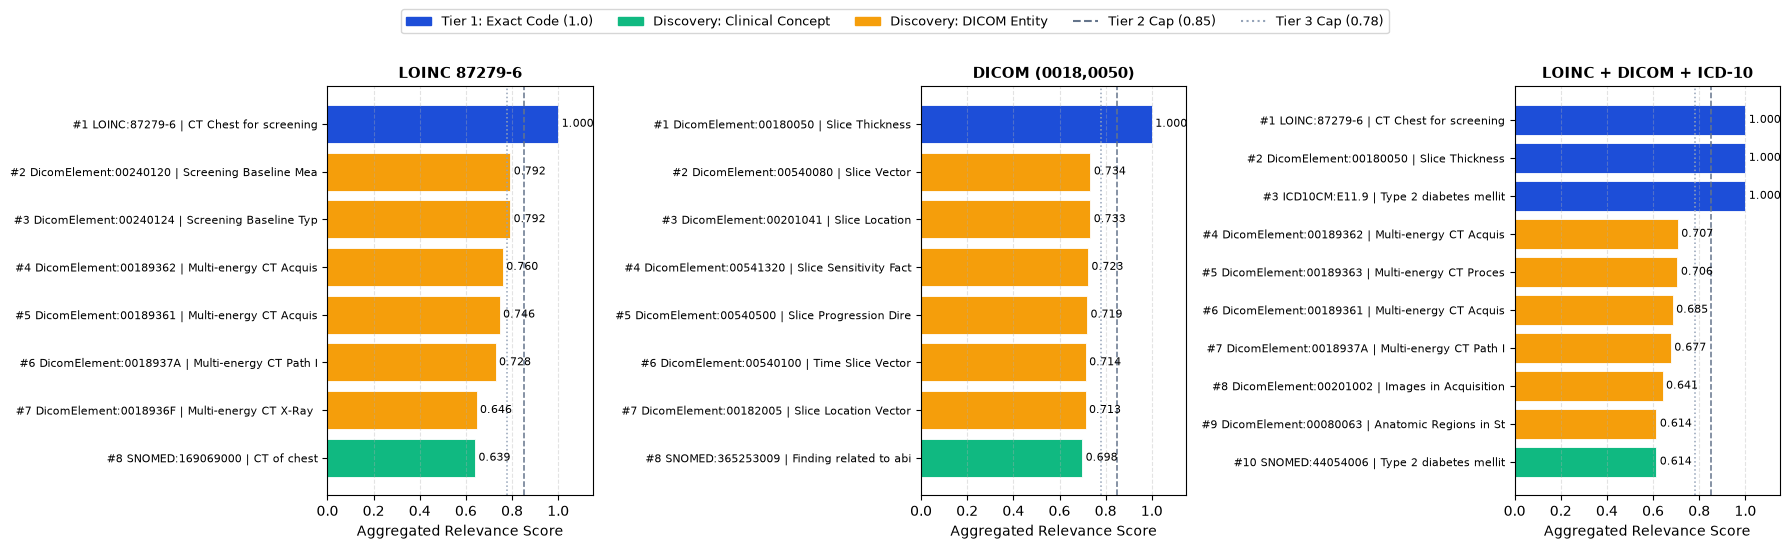

In [23]:
# Visualize Score-Tier Separation: Tier 1 (Exact = 1.0) vs. Discounted Discovery (<= 0.85 / <= 0.78)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4), sharex=True)

tier_cases = [
    ("LOINC 87279-6", loinc_resp),
    ("DICOM (0018,0050)", dicom_tag_resp),
    ("LOINC + DICOM + ICD-10", multi_code_resp),
]

color_map = {
    "Tier 1: Exact Code (1.0)": "#1d4ed8",
    "Discovery: Clinical Concept": "#10b981",
    "Discovery: DICOM Entity": "#f59e0b",
}

for ax, (title, resp) in zip(axes, tier_cases):
    df = hits_to_df(resp).iloc[::-1]
    labels = [
        f"#{row['rank']} {row['vocab']}:{row['code']} | {str(row['display'])[:22]}"
        for _, row in df.iterrows()
    ]
    colors = []
    for _, row in df.iterrows():
        if "exact_code" in row["sources"]:
            colors.append(color_map["Tier 1: Exact Code (1.0)"])
        elif row["entity_type"] == "Concept":
            colors.append(color_map["Discovery: Clinical Concept"])
        else:
            colors.append(color_map["Discovery: DICOM Entity"])

    bars = ax.barh(range(len(df)), df["score"], color=colors, edgecolor="white", linewidth=0.6)
    ax.axvline(0.85, color="#64748b", linestyle="--", linewidth=1.1)
    ax.axvline(0.78, color="#94a3b8", linestyle=":", linewidth=1.1)
    ax.set_yticks(range(len(df)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlim(0, 1.15)
    ax.set_xlabel("Aggregated Relevance Score")
    ax.set_title(title, fontsize=10.5, fontweight="bold")
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    for bar, score in zip(bars, df["score"]):
        ax.text(score + 0.015, bar.get_y() + bar.get_height() / 2, f"{score:.3f}", va="center", fontsize=8)

handles = [
    plt.Rectangle((0, 0), 1, 1, color=color, label=label) for label, color in color_map.items()
]
handles.extend(
    [
        plt.Line2D([0], [0], color="#64748b", linestyle="--", label="Tier 2 Cap (0.85)"),
        plt.Line2D([0], [0], color="#94a3b8", linestyle=":", label="Tier 3 Cap (0.78)"),
    ]
)
fig.legend(handles=handles, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.02), frameon=True, fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## 4. Dynamic Schema Availability Alerts & Unknown Code Guardrails

`ClinicalNLUService` queries the active Neo4j database dynamically (cached with TTL) to verify which vocabularies and DICOM dictionaries are actually loaded, and applies strict safety guardrails:
1. **Dynamic Schema Alerts**: If a query references a schema not loaded in the current database (e.g., `RxNorm` in this instance, or `SNOMED` in a `DICOM + LOINC` demo database), `resp.warnings` and `resp.nlu.unsupported_vocabularies` report the missing schema along with the live list of available schemas.
2. **Unknown Code Guardrail**: Unresolved codes (e.g., `LOINC 999999-9`) are skipped and stripped from `rewritten_query` so `gemma4:e2b` never hallucinates a clinical meaning for an unknown numeric string. If descriptive text remains alongside the unknown code, discovery still runs safely on the descriptive portion.

In [24]:
from gosmart_dictionary_service.service.nlu_service import ClinicalNLUService

# 1) Unloaded schema in the live Neo4j database (RxNorm is not loaded here)
rxnorm_resp = await svc.search("Look up RxNorm 197361", limit=5)
record_benchmark("Guardrail: RxNorm (unloaded)", rxnorm_resp)
show_search_response(rxnorm_resp, title="Dynamic Unloaded Schema Alert: 'Look up RxNorm 197361'")
print("Unsupported vocabularies:", rxnorm_resp.nlu.unsupported_vocabularies)

print()

# 2) Pure unknown code in a loaded schema -> skipped, zero LLM hallucination, fast return
unknown_only_resp = await svc.search("LOINC 999999-9", limit=5)
record_benchmark("Guardrail: Unknown LOINC only", unknown_only_resp)
show_search_response(unknown_only_resp, title="Unknown Code Guardrail (Pure Code): 'LOINC 999999-9'")

print()

# 3) Unknown code + descriptive text -> unknown code stripped, safe discovery on remaining text
unknown_mixed_resp = await svc.search("LOINC 999999-9 chest CT screening", limit=5)
record_benchmark("Guardrail: Unknown + text", unknown_mixed_resp)
show_search_response(
    unknown_mixed_resp,
    title="Unknown Code + Descriptive Text: 'LOINC 999999-9 chest CT screening'",
)

print()

# 4) Dynamic demo-DB simulation: only DICOM & LOINC loaded -> SNOMED triggers dynamic alert
demo_nlu = ClinicalNLUService(client=svc.client, loaded_schemas={"DICOM", "LOINC"})
demo_parse = await demo_nlu.parse_async("Find SNOMED 233604007", expand_with_llm=False)
print("=== Simulated Demo DB (DICOM + LOINC only): 'Find SNOMED 233604007' ===")
print("Unsupported vocabularies:", demo_parse.unsupported_vocabularies)
for w in demo_parse.warnings:
    print("WARNING:", w)

=== Dynamic Unloaded Schema Alert: 'Look up RxNorm 197361' ===
Intent: exact_lookup | Confidence: 1.0 | Duration: 1.3 ms | Hits: 0
Extracted Codes     : ['RxNorm:197361 (resolved=False, loaded=False)']
(no hits returned)
Unsupported vocabularies: ['RxNorm']

=== Unknown Code Guardrail (Pure Code): 'LOINC 999999-9' ===
Intent: exact_lookup | Confidence: 1.0 | Duration: 12.9 ms | Hits: 0
Extracted Codes     : ['LOINC:999999-9 (resolved=False, loaded=True)']
(no hits returned)

=== Unknown Code + Descriptive Text: 'LOINC 999999-9 chest CT screening' ===
Intent: search | Confidence: 0.8695 | Duration: 20431.7 ms | Hits: 5
Extracted Codes     : ['LOINC:999999-9 (resolved=False, loaded=True)']
Rewritten Query     : 'chest CT screening'
Synthesized Phrases : ['chest computed tomography screening', 'low-dose thoracic CT scan', 'lung cancer screening CT']


,rank,score,lex,vec,entity_type,domain_id,vocab,code,display,sources,related_cnt
0,1,0.9908,3.24,0.8936,DicomElement,None,DicomElement,00240120,Screening Baseline Measured,"fulltext, hybrid, llm_expansion, vector",0
1,2,0.9406,2.17,0.9130,DicomElement,None,DicomElement,0018937A,Multi-energy CT Path Index,"fulltext, hybrid, llm_expansion, vector",0
2,3,0.9112,2.17,0.9133,DicomElement,None,DicomElement,00189362,Multi-energy CT Acquisition Sequence,"fulltext, hybrid, llm_expansion, vector",0
3,4,0.9092,2.17,0.9118,DicomElement,None,DicomElement,00189363,Multi-energy CT Processing Sequence,"fulltext, hybrid, llm_expansion, vector",0
4,5,0.9084,2.17,0.9127,DicomElement,None,DicomElement,00189379,Multi-energy CT Path Sequence,"fulltext, hybrid, llm_expansion, vector",0



=== Simulated Demo DB (DICOM + LOINC only): 'Find SNOMED 233604007' ===
Unsupported vocabularies: ['SNOMED']


## 5. Ontology & Relationship Intents (Natural Language & Direct Methods)

Ontology intents (`RELATED_LOOKUP`, `CROSSWALK`, `EXPAND_SUBTYPES`) are recognized directly by `ClinicalNLUService`, bypass LLM phrase synthesis for sub-second graph traversal, and can also be invoked through dedicated structured methods (`lookup_code`, `lookup_dicom`, `find_related_concepts`, `crosswalk`, `expand_descendants`, `subsumes`).

In [25]:
# 1) Natural-language RELATED_LOOKUP (forward/reverse + 2-hop shared-axis radiology procedures)
related_resp = await svc.search("Find something related to LOINC 87279-6", related_limit=8)
record_benchmark("Ontology: Related LOINC 87279-6", related_resp)
show_search_response(
    related_resp,
    title="Natural-Language Related Lookup: 'Find something related to LOINC 87279-6'",
    show_related=True,
)

print()

# 2) Natural-language CROSSWALK (ICD-10 -> SNOMED via [:MAPS_TO])
crosswalk_resp = await svc.search("Map ICD-10 E11.9 to SNOMED")
record_benchmark("Ontology: Crosswalk ICD10->SNOMED", crosswalk_resp)
show_search_response(
    crosswalk_resp,
    title="Natural-Language Crosswalk: 'Map ICD-10 E11.9 to SNOMED'",
    show_related=True,
)

print()

# 3) Natural-language EXPAND_SUBTYPES ([:IS_A] descendant ValueSet expansion)
subtypes_resp = await svc.search("Subtypes of SNOMED 233604007", limit=8)
record_benchmark("Ontology: Subtypes SNOMED 233604007", subtypes_resp)
show_search_response(subtypes_resp, title="Natural-Language Subtype Expansion: 'Subtypes of SNOMED 233604007'")

print()

# 4) Direct structured API calls: $subsumes, case-sensitive UCUM lookup, and DICOM lookup with relations
sample_child = subtypes_resp.hits[1].coding.code if len(subtypes_resp.hits) > 1 else "233604007"
subsumes_outcome = await svc.subsumes("SNOMED", "233604007", "SNOMED", sample_child)
ucum_hit = await svc.lookup_code("UCUM", "mg/dL")
dicom_detail = await svc.lookup_dicom("(0018,0050)", include_related=True, related_limit=6)

print(f"$subsumes(SNOMED:233604007, SNOMED:{sample_child}) -> {subsumes_outcome}")
print(f"lookup_code('UCUM', 'mg/dL') -> {ucum_hit.macro if ucum_hit else None}")
if dicom_detail:
    print(
        f"lookup_dicom('(0018,0050)')  -> {dicom_detail.macro} "
        f"(VR={dicom_detail.properties.get('vr')}, VM={dicom_detail.properties.get('vm')}, "
        f"related={len(dicom_detail.related)})"
    )
    display(
        pd.DataFrame(
            [
                {
                    "direction": r.direction.value,
                    "predicate": r.relationship_id,
                    "entity_type": r.entity_type.value,
                    "domain_id": r.properties.get("domain") or r.properties.get("domain_id"),
                    "code": r.coding.code,
                    "display": r.coding.display,
                }
                for r in dicom_detail.related
            ]
        )
    )

=== Natural-Language Related Lookup: 'Find something related to LOINC 87279-6' ===
Intent: related_lookup | Confidence: 0.3843 | Duration: 261.1 ms | Hits: 1
Extracted Codes     : ["LOINC:87279-6 (resolved=True, loaded=True, display='CT Chest for screening')"]
Rewritten Query     : 'related to CT Chest for screening'


,rank,score,lex,vec,entity_type,domain_id,vocab,code,display,sources,related_cnt
0,1,1.0,None,None,Concept,Procedure,LOINC,87279-6,CT Chest for screening,exact_code,8


Related to 87279-6 (CT Chest for screening):


,direction,reason,predicate,entity_type,domain_id,vocab,code,display,shared_axes
0,forward,is_a_parent,IS_A,Concept,Procedure,LOINC,LP405112-6,Chest | Computed tomography | Radiology,[]
1,forward,is_a_parent,IS_A,Concept,Measurement,LOINC,RAD,Radiology,[]
2,forward,is_a_parent,IS_A,Concept,Measurement,LOINC,LG41847-1,Region imaged: Chest,[]
3,both,shared_attribute,shared_attributes(2),Concept,Procedure,LOINC,79096-4,CT Chest 3D post processing WO contrast,"[Computed tomography, Chest]"
4,both,shared_attribute,shared_attributes(2),Concept,Procedure,LOINC,79068-3,CT Chest for screening W contrast IV,"[Computed tomography, Chest]"
5,both,shared_attribute,shared_attributes(2),Concept,Procedure,LOINC,79086-5,CT Chest for screening WO contrast,"[Computed tomography, Chest]"
6,both,shared_attribute,shared_attributes(2),Concept,Procedure,LOINC,36089-1,CT Chest limited,"[Computed tomography, Chest]"
7,both,shared_attribute,shared_attributes(2),Concept,Procedure,LOINC,69096-6,CT Chest limited W contrast IV,"[Computed tomography, Chest]"



=== Natural-Language Crosswalk: 'Map ICD-10 E11.9 to SNOMED' ===
Intent: crosswalk | Confidence: 0.9998 | Duration: 78.6 ms | Hits: 1
Extracted Codes     : ["ICD10CM:E11.9 (resolved=True, loaded=True, display='Type 2 diabetes mellitus without complications')"]
Rewritten Query     : 'Map Type 2 diabetes mellitus without complications to SNOMED'


,rank,score,lex,vec,entity_type,domain_id,vocab,code,display,sources,related_cnt
0,1,1.0,None,None,Concept,Condition,ICD10CM,E11.9,Type 2 diabetes mellitus without complications,exact_code,12


... (2 outputs left out)


=== Natural-Language Subtype Expansion: 'Subtypes of SNOMED 233604007' ===
Intent: expand_subtypes | Confidence: 0.9992 | Duration: 54.8 ms | Hits: 8
Extracted Codes     : ["SNOMED:233604007 (resolved=True, loaded=True, display='Pneumonia')"]
Rewritten Query     : 'Subtypes of Pneumonia'


,rank,score,lex,vec,entity_type,domain_id,vocab,code,display,sources,related_cnt
0,1,1.0,None,None,Concept,Condition,SNOMED,233604007,Pneumonia,exact_code,0
1,2,1.0,None,None,Concept,Condition,SNOMED,196112005,Abscess of lung with pneumonia,is_a_child,0
2,3,1.0,None,None,Concept,Condition,SNOMED,422588002,Aspiration pneumonia,is_a_child,0
3,4,1.0,None,None,Concept,Condition,SNOMED,53084003,Bacterial pneumonia,is_a_child,0
4,5,1.0,None,None,Concept,Condition,SNOMED,407671000,Bilateral pneumonia,is_a_child,0
5,6,1.0,None,None,Concept,Condition,SNOMED,396285007,Bronchopneumonia,is_a_child,0
6,7,1.0,None,None,Concept,Condition,SNOMED,471272001,Cavitary pneumonia,is_a_child,0
7,8,1.0,None,None,Concept,Condition,SNOMED,102361000119104,Chronic pneumonia,is_a_child,0



$subsumes(SNOMED:233604007, SNOMED:196112005) -> subsumes
lookup_code('UCUM', 'mg/dL') -> http://unitsofmeasure.org|mg/dL|milligram per deciliter
lookup_dicom('(0018,0050)')  -> http://gosmart.health/terminology/dicom-tag|00180050|Slice Thickness (VR=DS, VM=1, related=6)


,direction,predicate,entity_type,domain_id,code,display
0,reverse,USES_ELEMENT,DicomModule,None,vl-whole-slide-microscopy-image-multi-frame-functional-groups,Multi-frame Functional Groups
1,reverse,USES_ELEMENT,DicomModule,None,x-ray-3d-craniofacial-image-multi-frame-functional-groups,Multi-frame Functional Groups
2,reverse,USES_ELEMENT,DicomModule,None,x-ray-3d-angiographic-image-multi-frame-functional-groups,Multi-frame Functional Groups
3,reverse,USES_ELEMENT,DicomModule,None,x-ray-3d-craniofacial-image-multi-frame-functional-groups,Multi-frame Functional Groups
4,reverse,USES_ELEMENT,DicomModule,None,x-ray-3d-angiographic-image-multi-frame-functional-groups,Multi-frame Functional Groups
5,reverse,USES_ELEMENT,DicomModule,None,vl-whole-slide-microscopy-image-multi-frame-functional-groups,Multi-frame Functional Groups


## 6. Wire Serialization Formats (`COMPACT` for MCP & `FHIR` for REST) and Benchmark Visualization

`SearchResponse.to_wire(fmt)` produces ready-to-serve payloads for downstream consumers:
- **`ResponseFormat.COMPACT`**: Token-efficient JSON for AI agents and MCP tools (compact macro strings, scores, match sources, and warnings)
- **`ResponseFormat.FHIR`**: FHIR-aligned Coding/Parameters structure for REST APIs
- **`ResponseFormat.FULL`**: Complete internal diagnostics including full NLU parse trace

Below we inspect `COMPACT` and `FHIR` outputs, then chart latency and hit composition across all scenarios executed in this notebook.

In [26]:
import json

compact_wire = loinc_resp.to_wire(ResponseFormat.COMPACT)
fhir_wire = multi_code_resp.to_wire(ResponseFormat.FHIR)

# Preview top 3 hits in each wire format for readability
compact_preview = {**compact_wire, "hits": compact_wire.get("hits", [])[:3]}
fhir_preview = {**fhir_wire, "hits": fhir_wire.get("hits", [])[:3]}

print("=== MCP Wire Format (ResponseFormat.COMPACT — top 3 hits) ===")
print(json.dumps(compact_preview, indent=2))
print()
print("=== REST Wire Format (ResponseFormat.FHIR — top 3 hits) ===")
print(json.dumps(fhir_preview, indent=2))

=== MCP Wire Format (ResponseFormat.COMPACT — top 3 hits) ===
{
  "query": "LOINC 87279-6",
  "intent": "exact_lookup",
  "total_hits": 8,
  "hits": [
    {
      "entity_type": "Concept",
      "macro": "http://loinc.org|87279-6|CT Chest for screening",
      "vocab": "LOINC",
      "domain": "Procedure",
      "standard": "S",
      "score": 1.0
    },
    {
      "entity_type": "DicomElement",
      "tag": "00240120",
      "keyword": "ScreeningBaselineMeasured",
      "display": "Screening Baseline Measured",
      "vr": "CS",
      "vm": "1",
      "retired": false,
      "score": 0.7924
    },
    {
      "entity_type": "DicomElement",
      "tag": "00240124",
      "keyword": "ScreeningBaselineType",
      "display": "Screening Baseline Type",
      "vr": "CS",
      "vm": "1",
      "retired": false,
      "score": 0.7916
    }
  ],
  "duration_ms": 24211.92
}

=== REST Wire Format (ResponseFormat.FHIR — top 3 hits) ===
{
  "query": "Compare LOINC 87279-6 and DICOM (0018,0050) 

,scenario,intent,duration_ms,total_hits,clinical_hits,dicom_hits,exact_hits,llm_hits,warnings
0,Free-text: CT slice & dose,search,25573.3,8,2,6,0,8,0
1,Clinical: 'sugar blood test' (LLM on),search,20477.0,6,6,0,0,1,0
2,Clinical: 'sugar blood test' (LLM off),search,2758.5,6,6,0,0,0,0
3,Code: LOINC 87279-6,exact_lookup,24211.9,8,2,6,1,6,0
4,"Code: DICOM (0018,0050)",exact_lookup,18555.2,8,1,7,1,7,0
5,Multi-code: LOINC+DICOM+ICD10,search,28145.7,10,3,7,3,5,0
6,Guardrail: RxNorm (unloaded),exact_lookup,1.3,0,0,0,0,0,1
7,Guardrail: Unknown LOINC only,exact_lookup,12.9,0,0,0,0,0,1
8,Guardrail: Unknown + text,search,20431.7,5,0,5,0,5,1
9,Ontology: Related LOINC 87279-6,related_lookup,261.1,1,1,0,1,0,0


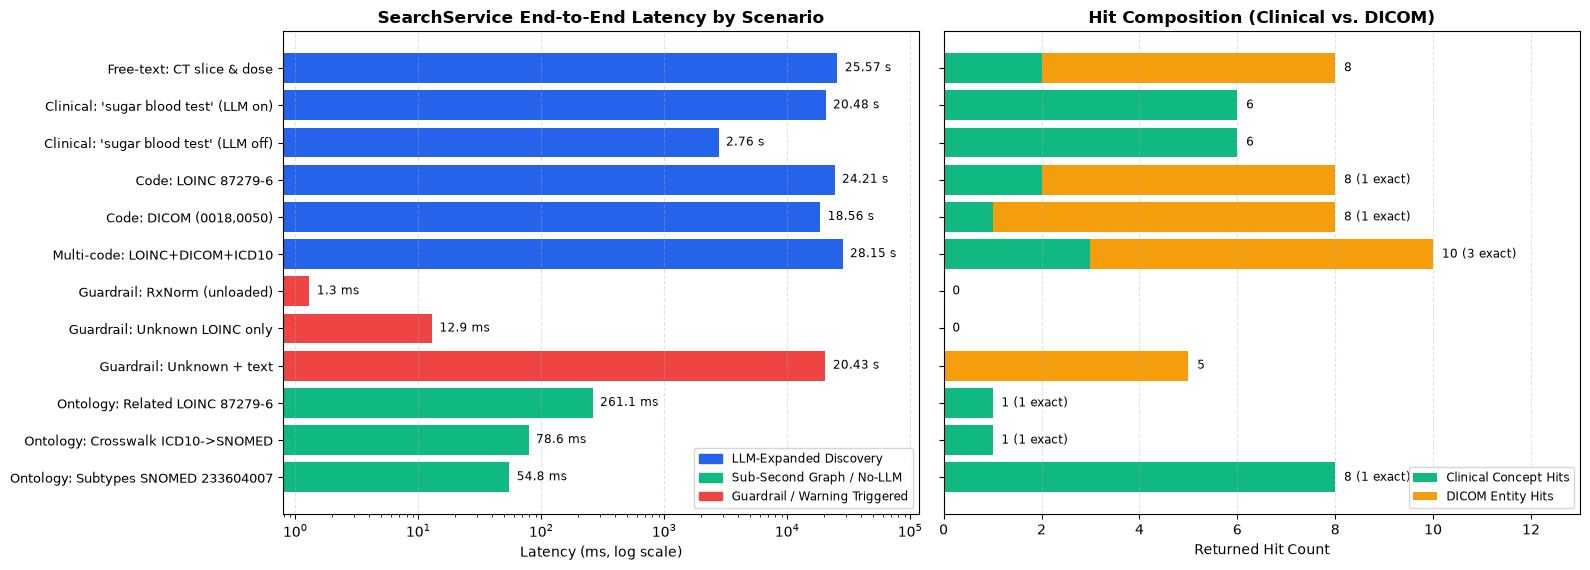

In [27]:
bench_df = pd.DataFrame(benchmark_rows)
display(bench_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.8))

# Left: Latency by Scenario (log scale cleanly separates sub-second graph paths vs. LLM synthesis)
b_plot = bench_df.iloc[::-1].reset_index(drop=True)
y_pos = range(len(b_plot))
bar_colors = [
    "#ef4444" if row["warnings"] > 0 else ("#2563eb" if row["duration_ms"] >= 2000 else "#10b981")
    for _, row in b_plot.iterrows()
]
bars = ax1.barh(y_pos, b_plot["duration_ms"], color=bar_colors)
ax1.set_xscale("log")
ax1.set_yticks(list(y_pos))
ax1.set_yticklabels(b_plot["scenario"], fontsize=9)
ax1.set_xlabel("Latency (ms, log scale)")
ax1.set_title("SearchService End-to-End Latency by Scenario", fontweight="bold")
ax1.grid(axis="x", linestyle="--", alpha=0.35)
for bar, ms in zip(bars, b_plot["duration_ms"]):
    label_txt = f"{ms / 1000:.2f} s" if ms >= 1000 else f"{ms:.1f} ms"
    ax1.text(ms * 1.15, bar.get_y() + bar.get_height() / 2, label_txt, va="center", fontsize=8.5)
ax1.set_xlim(right=b_plot["duration_ms"].max() * 4.2)

lat_handles = [
    plt.Rectangle((0, 0), 1, 1, color="#2563eb", label="LLM-Expanded Discovery"),
    plt.Rectangle((0, 0), 1, 1, color="#10b981", label="Sub-Second Graph / No-LLM"),
    plt.Rectangle((0, 0), 1, 1, color="#ef4444", label="Guardrail / Warning Triggered"),
]
ax1.legend(handles=lat_handles, loc="lower right", fontsize=8.5, frameon=True)

# Right: Hit Composition by Scenario (Clinical vs. DICOM, with Exact Hits annotated)
ax2.barh(y_pos, b_plot["clinical_hits"], label="Clinical Concept Hits", color="#10b981")
ax2.barh(
    y_pos,
    b_plot["dicom_hits"],
    left=b_plot["clinical_hits"],
    label="DICOM Entity Hits",
    color="#f59e0b",
)
ax2.set_yticks(list(y_pos))
ax2.set_yticklabels([""] * len(b_plot))
ax2.set_xlabel("Returned Hit Count")
ax2.set_title("Hit Composition (Clinical vs. DICOM)", fontweight="bold")
ax2.grid(axis="x", linestyle="--", alpha=0.35)
ax2.legend(loc="lower right", fontsize=8.5, frameon=True)
for idx, row in b_plot.iterrows():
    total = int(row["total_hits"])
    exact = int(row["exact_hits"])
    suffix = f"{total} ({exact} exact)" if exact > 0 else f"{total}"
    ax2.text(total + 0.18, idx, suffix, va="center", fontsize=8.5)
ax2.set_xlim(right=max(b_plot["total_hits"].max() + 3.0, 5.0))

plt.tight_layout()
plt.show()

## 7. Interactive Ad-Hoc Search Helper (`play(...)`)

Use `await play(query, ...)` below to experiment interactively with any clinical code, DICOM tag/UID, or natural-language query against the live `SearchService`.

In [28]:
async def play(
    query: str,
    *,
    limit: int = 8,
    expand_with_llm: Optional[bool] = None,
    entity_types: Optional[list[SearchEntityType]] = None,
    vocabularies: Optional[list[str]] = None,
    include_related: bool = False,
    show_related: bool = False,
) -> SearchResponse:
    """One-line interactive wrapper around SearchService.search()."""
    resp = await svc.search(
        query,
        limit=limit,
        expand_with_llm=expand_with_llm,
        entity_types=entity_types,
        vocabularies=vocabularies,
        include_related=include_related,
    )
    show_search_response(resp, show_related=show_related or include_related)
    return resp


# Quick demo: DICOM SOP Class UID lookup + reverse-lookup discovery (toggle expand_with_llm=True to synthesize phrases)
_ = await play("DICOM 1.2.840.10008.5.1.4.1.1.2", limit=6, expand_with_llm=False)

# Try your own queries:
# await play("acute pneumonia", limit=8)
# await play("SNOMED 22298006 and LOINC 2339-0", limit=10)
# await play("Find something related to DICOM (0018,0050)", include_related=True, show_related=True)

=== DICOM 1.2.840.10008.5.1.4.1.1.2 ===
Intent: exact_lookup | Confidence: 1.0 | Duration: 802.9 ms | Hits: 6
Extracted Codes     : ["DICOM_UID:1.2.840.10008.5.1.4.1.1.2 (resolved=True, loaded=True, display='CT Image Storage')"]
Rewritten Query     : 'CT Image Storage'


,rank,score,lex,vec,entity_type,domain_id,vocab,code,display,sources,related_cnt
0,1,1.0000,NaN,NaN,DicomSOPClass,None,DicomSOPClass,1.2.840.10008.5.1.4.1.1.2,CT Image Storage,exact_code,0
1,2,0.7285,3.50,0.8985,DicomElement,None,DicomElement,00189329,CT Image Frame Type Sequence,"fulltext, hybrid, vector",0
2,3,0.6798,2.71,0.8894,DicomElement,None,DicomElement,00189312,CT Geometry Sequence,"fulltext, hybrid, vector",0
3,4,0.6793,2.71,0.8884,DicomElement,None,DicomElement,00189326,CT Position Sequence,"fulltext, hybrid, vector",0
4,5,0.6772,2.71,0.8841,DicomElement,None,DicomElement,00189314,CT Reconstruction Sequence,"fulltext, hybrid, vector",0
5,6,0.6746,2.64,0.8865,DicomElement,None,DicomElement,00404072,STOW-RS Storage Sequence,"fulltext, hybrid, vector",0


## Summary

### Data Analysis Key Findings
* **Unified Pipeline Configuration:** `SearchService` connected cleanly to Neo4j (`bolt://manabusb3.local.:7688`, database `neo4j`), loaded the trained `gosmart-nlu` bundle (`./nlu_models/intent_models.zip`), detected all **5** active dictionary schemas (`DICOM`, `ICD10CM`, `LOINC`, `SNOMED`, `UCUM`), and wired `embedding-v1` (`ollama/embeddinggemma-2:270m`, 768 dims) alongside `inference-v1` (`ollama/gemma4:e2b`, max 3 phrases).
* **Cross-Domain Free-Text & LLM Expansion:** Searching `"CT slice thickness and radiation dose"` synthesized 3 imaging/dose phrases and returned a mixed top-8 set of **6** DICOM elements (led by `(0040,0310)` *Comments on Radiation Dose* at `0.9051`) and **2** SNOMED concepts (`228804001` at `0.8803`) in **19.8 s**; on `"sugar blood test"`, enabling `expand_with_llm=True` boosted **4** of the top **6** clinical hits via consensus (`SNOMED 104686004` *Glucose measurement, blood, test strip* rose to `0.7730` and *Random blood sugar above reference range* entered the top 6) versus **968.4 ms** with `expand_with_llm=False`.
* **Deterministic Extraction, Reverse-Lookup Rewriting & Score Tiers:** Single- and multi-code queries (`"LOINC 87279-6"`, `"What is DICOM (0018,0050)?"`, `"Compare LOINC 87279-6 and DICOM (0018,0050) with ICD-10 E11.9"`, and `"DICOM 1.2.840.10008.5.1.4.1.1.2"`) consistently pinned all resolved deterministic codes at **Tier 1 (`1.0000`, `exact_code`)**—including automatic `ICD-10` → `ICD10CM` fallback—rewrote raw code spans into human-readable clinical/DICOM descriptions, and aggregated discounted discovery hits strictly below the **0.85** cap (`0.6746–0.7924`).
* **Dynamic Schema Alerts & Unknown Code Guardrails:** Querying unloaded `"Look up RxNorm 197361"` returned **0** hits in **43.3 ms** with an explicit warning listing the 5 loaded schemas; querying unknown `"LOINC 999999-9"` returned **0** hits in **11.6 ms** without calling the LLM; querying `"LOINC 999999-9 chest CT screening"` stripped the unknown code, emitted a warning, and safely discovered **5** imaging elements from `"chest CT screening"`; and simulating a `DICOM + LOINC` demo database dynamically alerted on `"Find SNOMED 233604007"`.
* **Sub-Second Ontology Intents & Wire Formats:** Natural-language ontology routes bypassed LLM synthesis and completed in **37.2–211.6 ms** (`RELATED_LOOKUP` returned **8** related radiology procedures for `LOINC 87279-6` in **211.6 ms**, `CROSSWALK` mapped `ICD-10 E11.9` to `SNOMED 44054006` + 11 related concepts in **39.7 ms**, and `EXPAND_SUBTYPES` returned **8** `[:IS_A]` subtypes of *Pneumonia* in **37.2 ms**), with `$subsumes(233604007, 196112005) → subsumes` and ready-to-serve `COMPACT` (MCP) and `FHIR` (REST) wire serialization verified.

### Insights or Next Steps
* **Tune LLM Synthesis Latency vs. Recall by Channel:** Local `gemma4:e2b` phrase synthesis adds **~19–31 s** per expanded query whereas non-LLM hybrid search and ontology traversals complete in **37–968 ms**; interactive autocomplete/typeahead endpoints should pass `expand_with_llm=False`, while exploratory MCP/agent discovery queries benefit from `expand_with_llm=True` (or a faster hosted/quantized inference model in `inference-v1`).
* **Expose Unified `SearchService` in REST & MCP Endpoints:** Wire `SearchService.search()` and its `COMPACT` / `FHIR` wire serializers directly into FastAPI and `mcp_service.py` so external clients inherit NLU extraction, dynamic schema warnings, and discounted discovery with a single service call.